Modelo 1

In [100]:
# Inicio -> treino sem sobolev


import numpy as np



class model1:
    def __init__(self, w1, w2, EPOCHS=100, LR=0.1, TOL=1e-6, data=None):
        self.w1 = w1
        self.w2 = w2
        self.epochs = EPOCHS
        self.lr = LR
        self.tol = TOL
        self.data = data
        self.errors = []

    def erro(self,yp, y):
        return np.mean((yp - y) ** 2)

    def f(self, x):
        return x**2

    def relu(self,x):
        return np.maximum(x, 0)

    def d_relu(self, x):
        return (x > 0).astype(int)


    def df(self, x):
        return 2*x

    def forward(self, x):
        return self.relu(self.w1 * x) * self.w2

    def error(self, yi, y):
        return (yi-y)**2

    def backprop(self, yi, data):
        dw2 = 2*(yi-data[1])*self.relu(self.w1*data[0])
        dw1 = 2*(yi-data[1])*self.w2*self.d_relu(self.w1*data[0])*data[0]

        self.w1 -= self.lr*dw1
        self.w2 -= self.lr*dw2

        return dw1, dw2
        
    def train(self):
        for epoch in range(self.epochs):
            y_pred = self.forward(self.data[0])
            erro = self.error(y_pred, self.data[1])
            if erro < self.tol:
                    print(f'Training stopped at epoch {epoch} with error {erro}')
                    break
            self.errors.append(erro)
            dw1,dw2 = self.backprop(y_pred, self.data)

            print(f'Epoch: {epoch}, Error: {erro}, w1: {self.w1}, w2: {self.w2}')





    

In [101]:
model = model1(w1=0.5, w2=1, EPOCHS=1000, LR=0.01, TOL=1e-6, data=np.array([2, 4]))

In [102]:
model.train()

Epoch: 0, Error: 9.0, w1: 0.62, w2: 1.06
Epoch: 1, Error: 7.21244736, w1: 0.73386944, w2: 1.12660288
Epoch: 2, Error: 5.505786073717232, w1: 0.8396097343253468, w2: 1.1954821381304048
Epoch: 3, Error: 3.970148380655156, w1: 0.9348907662792698, w2: 1.2623998104012655
Epoch: 4, Error: 2.6882492944269325, w1: 1.017683396956344, w2: 1.3237132431966676
Epoch: 5, Error: 1.7050040071469605, w1: 1.0868213643028641, w2: 1.376867173498028
Epoch: 6, Error: 1.0144169510331689, w1: 1.142291635099035, w2: 1.4206522796762675
Epoch: 7, Error: 0.5691217274346652, w1: 1.1851613274553912, w2: 1.4551221437510244
Epoch: 8, Error: 0.3034809126163654, w1: 1.2172258761608679, w2: 1.4812379329108813
Epoch: 9, Error: 0.1552342022775121, w1: 1.2405700508128605, w2: 1.5004213016409702
Epoch: 10, Error: 0.07686453449688328, w1: 1.2572093953059402, w2: 1.5141789525225569
Epoch: 11, Error: 0.03714099432523193, w1: 1.2688818973748464, w2: 1.523870527777456
Epoch: 12, Error: 0.017629611358959026, w1: 1.276975268027929

In [89]:
model.forward(2)

np.float64(3.9999999999999982)

Modelo2 com Bias

In [ ]:
# Inicio -> treino sem sobolev


import numpy as np

class ModeWithBias:
    def __init__(self, w1, w2, EPOCHS=100, LR=0.1, TOL=1e-6, patience = 5, data=None):
        self.w1 = w1
        self.w2 = w2
        self.b1 = 0.0
        self.b2 = 0.0
        self.epochs = EPOCHS
        self.lr = LR
        self.tol = TOL
        self.patience = patience
        self.data = data
        self.errors = []


    def f(self, x):
        return x**2

    def relu(self,x):
        return np.maximum(x, 0)

    def d_relu(self, x):
        return (x > 0).astype(int)


    def df(self, x):
        return 2*x

    def forward(self, x):
        return self.relu(self.w1 * x + self.b1) * self.w2 + self.b2

    def error(self, yi, y):
        return np.mean((yi-y)**2)

    def backprop(self, yi, data):
        dw2 = 2*(yi-data[1])*self.relu(self.w1*data[0] + self.b1)
        dw1 = 2*(yi-data[1])*self.w2*self.d_relu(self.w1*data[0] + self.b1)*data[0]
        db1 = 2*(yi-data[1])*self.w2*self.d_relu(self.w1*data[0] + self.b1)
        db2 = 2*(yi-data[1])

        self.w1 -= self.lr*np.mean(dw1)
        self.w2 -= self.lr*np.mean(dw2)
        self.b1 -= self.lr*np.mean(db1)
        self.b2 -= self.lr*np.mean(db2)

        return dw1, dw2
        
    def train(self):
        for epoch in range(self.epochs):
            y_pred = self.forward(self.data[0])
            erro = self.error(y_pred, self.data[1])
            self.errors.append(erro)
            dw1,dw2 = self.backprop(y_pred, self.data)

            print(f'Epoch: {epoch}, Error: {erro}, w1: {self.w1}, w2: {self.w2}', f'b1: {self.b1}, b2: {self.b2}')

           




    

In [82]:
model2 = ModeWithBias(w1=0.5, w2=1, EPOCHS=100000, LR=0.01, TOL=1e-13, data=np.array([[2], [4]]))

In [83]:
model2.train()

Epoch: 0, Error: 9.0, w1: 0.62, w2: 1.06 b1: 0.06, b2: 0.06
Epoch: 1, Error: 6.563844, w1: 0.7286288, w2: 1.1266120000000002 b1: 0.11431440000000001, b2: 0.11124
Epoch: 2, Error: 4.486805664781299, w1: 0.8240847477270803, w2: 1.19319033161787 b1: 0.16204237386354017, b2: 0.15360416251872
Epoch: 3, Error: 2.844176125722541, w1: 0.904575865836083, w2: 1.2542476388699344 b1: 0.20228793291804154, b2: 0.18733353325534977
Epoch: 4, Error: 1.6636434144169558, w1: 0.9692861647664788, w2: 1.3061356623918927 b1: 0.23464308238323944, b2: 0.21312999358941076
Epoch: 5, Error: 0.8993788274228826, w1: 1.0188334208726397, w2: 1.3473552935865887 b1: 0.25941671043631986, b2: 0.2320971106863539
Epoch: 6, Error: 0.4528148737541904, w1: 1.0550996554416945, w2: 1.3782701425965993 b1: 0.2775498277208473, b2: 0.24555541479577558
Epoch: 7, Error: 0.21481485932698066, w1: 1.0806517496014882, w2: 1.4004036812019696 b1: 0.2903258748007442, b2: 0.25482503958488073
Epoch: 8, Error: 0.09728420509855869, w1: 1.098123

In [85]:
model2.forward(2)

np.float64(3.999999999999999)

modelo mais robusto com 3 neuronios

In [162]:
class model3N:
    def __init__ (self, EPOCHS=100, LR=0.01, delta= 0.1, TOL=1e-6, data=None):
        self.W1 = np.array([-1, 0, 1], dtype=float)
        self.b1 = np.array([-1, 0, 1], dtype=float)
        self.W2 = np.array([0], dtype=float)
        self.epochs = EPOCHS
        self.lr = LR
        self.tol = TOL
        self.data = data
        self.errors = []

    def relu(self,x):
        return np.maximum(x, 0)

    def d_relu(self,x):
        return (x>0).astype(float) 

    def forward(self, x):
        h = self.W1 * x + self.b1
        return np.sum(self.relu(h) * self.W2)

    def error(self, yi, y):
        return np.mean((yi-y)**2)

    def backprop(self, yi, data):
        x = data[0]
        y = data[1]

        h = self.W1 * x + self.b1

        dw2 = 2 * (yi - y) * self.relu(h)
        db1 = 2 * (yi - y) * self.W2 * self.d_relu(h)
        dw1 = db1 * x

        # Atualização direta dos vetores (sem np.mean, pois estamos avaliando 1 amostra por vez)
        self.W1 -= self.lr * np.mean(dw1)
        self.b1 -= self.lr * np.mean(db1)
        self.W2 -= self.lr * np.mean(dw2)

    def train(self):
        for epoch in range(self.epochs):
            y_pred = self.forward(self.data[0])
            erro = self.error(y_pred, self.data[1])
            self.errors.append(erro)
            self.backprop(y_pred, self.data)

            print(f'Epoch: {epoch}, Error: {erro}, W1: {self.W1}, b1: {self.b1}, W2: {self.W2}')



In [166]:
model3 = model3N(EPOCHS=1000, LR=0.01, TOL=1e-6, data=np.array([[2, 3, 4], [4, 9, 16]]))

In [168]:
print(model3.W)
x = model3.W
data = model3.data
print(np.einsum('j,j->j', x, data[0]))
a = np.einsum('j,j->j', x, data[0])

b = 2

print(np.sum(a))

AttributeError: 'model3N' object has no attribute 'W'

In [169]:
model3.train()

Epoch: 0, Error: 117.66666666666667, W1: [-1.  0.  1.], b1: [-1.  0.  1.], W2: [0.53333333]
Epoch: 1, Error: 73.22222222222223, W1: [-0.81037037  0.18962963  1.18962963], b1: [-0.95259259  0.04740741  1.04740741], W2: [0.97777778]
Epoch: 2, Error: 35.69507843316568, W1: [-0.50371673  0.49628327  1.49628327], b1: [-0.87149578  0.12850422  1.12850422], W2: [1.36519843]
Epoch: 3, Error: 29.297640906421694, W1: [-0.43488114  0.56511886  1.56511886], b1: [-0.8609298  0.1390702  1.1390702], W2: [1.5272319]
Epoch: 4, Error: 43.89810507341719, W1: [-0.51345132  0.48654868  1.48654868], b1: [-0.89355997  0.10644003  1.10644003], W2: [1.55844016]
Epoch: 5, Error: 38.39815499055229, W1: [-0.54485207  0.45514793  1.45514793], b1: [-0.91292121  0.08707879  1.08707879], W2: [1.6329224]
Epoch: 6, Error: 40.101489971199044, W1: [-0.5945019  0.4054981  1.4054981], b1: [-0.93799303  0.06200697  1.06200697], W2: [1.69602817]
Epoch: 7, Error: 38.952149549934745, W1: [-0.63444198  0.36555802  1.36555802], 

In [170]:
model3.forward(2)

np.float64(6.579646812661422)

Com sobolev

In [ ]:
import numpy as np

class modelSoboloev:
    def __init__ (self, w1, w2, EPOCHS=100, LR=0.01, delta= 0.1, TOL=1e-6, data=None):
        self.w1 = w1
        self.w2 = w2
        self.epochs = EPOCHS
        self.lr = LR
        self.tol = TOL
        self.data = data
        self.delta =delta

        self.errors = []

    def f(self, x):
        return x**2

    def relu(self,x):
        return np.maximum(x, 0)

    def d_relu(self, x):
        return (x > 0).astype(int)

    def df(self, data):
        return 2 * data

    def error(self, yi, y, data):
        return np.mean((yi-y)**2 ) 

    def dypre_dx(self, x):
        return self.w2 * self.d_relu(self.w1 * x ) * self.w1

    def error_sobolev(self, yi, data):
        y = data[1]
        x = data[0]
        return np.mean((yi-y)**2 ) + np.mean((self.df(x) - self.dypre_dx(x))**2)
 
    def backprop(self, yi, data):

        x, y = data[0], data[1]
        h = self.w1*x

        dvw2 =(2*(yi - y) * self.relu(h))
        dvw1 =(2*(yi - y) * self.w2 * self.d_relu(h)*x)

        grad_p = self.dypre_dx(x)
        grad_r = self.df(x)

        error_grad_w2 = 2*(grad_p - grad_r)*self.d_relu(h)*self.w1
        error_grad_w1 = 2 * (grad_p - grad_r) * self.w2 * self.d_relu(h)

        grad_w2 = np.mean(dvw2 + error_grad_w2)
        grad_w1 = np.mean(dvw1 + error_grad_w1)

        self.w1 -= self.delta*grad_w1
        self.w2 -= self.delta*grad_w2
    

    def forward(self, x):
        z1 = self.w1 * x
        a1 = self.relu(z1)
        z2 = self.w2 * a1
        return z2

    def train(self):
        x = self.data[0]
        for epoch in range(self.epochs):
            y_pred = self.forward(x)
            Lsobolev = self.error_sobolev(y_pred, self.data)
            print(f'Error Sobolev: {Lsobolev}, w1: {self.w1}, w2: {self.w2}')
            if Lsobolev < self.tol:
                print(f'Training stopped with error {Lsobolev}')
                return
            self.backprop(y_pred, self.data)

        


In [116]:
modelS = modelSoboloev(w1=0.5, w2=1, EPOCHS=1000, LR=0.01, delta=0.01, TOL=1e-6, data=np.array([[2], [4]]))

In [117]:
modelS.train()

Error Sobolev: 21.25, w1: 0.5, w2: 1
Error Sobolev: 16.721079012500002, w1: 0.69, w2: 1.095
Error Sobolev: 12.292967431077619, w1: 0.8700672749999999, w2: 1.2084670499999999
Error Sobolev: 8.50863627967059, w1: 1.0330353850573037, w2: 1.3258001783045394
Error Sobolev: 5.8265384640520015, w1: 1.169646034604251, w2: 1.43224429957335
Error Sobolev: 4.295820895789826, w1: 1.2734523994253129, w2: 1.5170180375563225
Error Sobolev: 3.5927269790177725, w1: 1.3444715594265806, w2: 1.576634678538699
Error Sobolev: 3.325244555152912, w1: 1.3886582464761408, w2: 1.6143147732696348
Error Sobolev: 3.236930089073522, w1: 1.414207760644066, w2: 1.6362928559398986
Error Sobolev: 3.2103841347583844, w1: 1.4282703796158902, w2: 1.6484468324195616
Error Sobolev: 3.2028424664414707, w1: 1.4357827172726847, w2: 1.6549557771703751
Error Sobolev: 3.2007668254873263, w1: 1.4397286444329573, w2: 1.6583791278716387
Error Sobolev: 3.2002052815580204, w1: 1.441782392135565, w2: 1.6601620973664837
Error Sobolev: 3.

In [111]:
modelS.forward(2)

np.float64(4.799999999999999)

2 Camadas


In [280]:
import numpy as np

class model2C:
    def __init__(self, EPOCHS=10000, LR=0.05, delta=0.05, TOL=1e-5, data=None):
        np.random.seed(42)  # Semente estável para convergência com Tanh
        
        # Dimensões da Rede 1-10-10-1
        n_in, n_h1, n_h2, n_out = 1, 3, 3, 1
        
        # Inicialização de Xavier (Glorot) para Tanh
        self.W1 = np.random.randn(n_in, n_h1) * np.sqrt(2.0 / (n_in + n_h1))
        self.b1 = np.zeros((1, n_h1))
        
        self.W2 = np.random.randn(n_h1, n_h2) * np.sqrt(2.0 / (n_h1 + n_h2))
        self.b2 = np.zeros((1, n_h2))
        
        self.W3 = np.random.randn(n_h2, n_out) * np.sqrt(2.0 / (n_h2 + n_out))
        self.b3 = np.zeros((1, n_out))

        self.epochs = EPOCHS
        self.lr = LR
        self.tol = TOL
        self.data = data
        self.errors = []

    def tanh(self, x):
        return np.tanh(x)

    def d_tanh(self, x):
        return 1.0 - np.tanh(x) ** 2
    
    

    def error(self, yi, y):
        return np.mean((yi - y) ** 2)


    def forward(self, x):
        # Armazena h e a no self para reutilização no backprop
        self.h1 = x @ self.W1 + self.b1
        self.a1 = self.tanh(self.h1)
        
        self.h2 = self.a1 @ self.W2 + self.b2
        self.a2 = self.tanh(self.h2)
        
        self.h3 = self.a2 @ self.W3 + self.b3
        return self.h3

  


    def backprop(self, dL, x):
        m = x.shape[0]
        # print(f'dL: {dL}')
        # print(f'm: {m}')
        # Gradientes da Camada 3
        dw3 = (self.a2.T @ dL) / m
        # print(f'dw3: {dw3}')
        db3 = np.sum(dL, axis=0, keepdims=True) / m
        # print(f'db3: {db3}')
        
        # Gradientes da Camada 2 (usa as variáveis salvas no forward)
        dh2 = (dL @ self.W3.T) * self.d_tanh(self.h2)
        # print(f'dh2: {dh2}')
        dw2 = (self.a1.T @ dh2) / m
        # print(f'dw2: {dw2}')
        db2 = np.sum(dh2, axis=0, keepdims=True) / m
        # print(f'db2: {db2}')
        
        # Gradientes da Camada 1
        dh1 = (dh2 @ self.W2.T) * self.d_tanh(self.h1)
        # print(f'dh1: {dh1}')
        dw1 = (x.T @ dh1) / m
        # print(f'dw1: {dw1}')
        db1 = np.sum(dh1, axis=0, keepdims=True) / m
        # print(f'db1: {db1}')
        
        # Atualização Gradual dos Parâmetros
        self.W3 -= self.lr * dw3
        self.W2 -= self.lr * dw2
        self.b2 -= self.lr * db2
        self.W1 -= self.lr * dw1
        self.b1 -= self.lr * db1
        self.b3 -= self.lr * db3

        # print(f"Pesos atualizados: W1={self.W1}, \nb1={self.b1}, \nW2={self.W2}, \nb2={self.b2}, \nW3={self.W3}, \nb3={self.b3}")

    def train(self):
        print("Iniciando treinamento...")
        print(f"Pesos iniciais: W1={self.W1}, \nb1={self.b1}, \nW2={self.W2}, \nb2={self.b2}, \nW3={self.W3}, \nb3={self.b3}")
        x = self.data[:, 0][:, np.newaxis]
        y_true = self.data[:, 1][:, np.newaxis]
        
        for epoch in range(self.epochs):
            y_pred = self.forward(x)
            erro = self.error(y_pred, y_true)
            self.errors.append(erro)
            
            if erro < self.tol:
                print(f'💥 Convergiu na época {epoch}! Erro final: {erro:.6e}')
                break
                
            # Calcula a derivada da perda diretamente para passar ao backprop
            dL = 2 * (y_pred - y_true)
            self.backprop(dL, x)
            
            if epoch % 100 == 0:
                print(f'Época: {epoch} | Erro: {erro:.4f}')





In [242]:
def normalize_data(data, max_val, min_val):
    """
    Normaliza os dados para o intervalo [0, 1].
    
    Parâmetros:
    data (np.ndarray): Array de dados a ser normalizado.
    
    Retorna:
    np.ndarray: Dados normalizados.
    """
    return (data - min_val) / (max_val - min_val)

def denormalize_data(normalized_data, original_data):
    """
    Desnormaliza os dados normalizados de volta ao intervalo original.
    
    Parâmetros:
    normalized_data (np.ndarray): Array de dados normalizados.
    original_data (np.ndarray): Array de dados originais para referência.
    
    Retorna:
    np.ndarray: Dados desnormalizados.
    """
    min_val = np.min(original_data, axis=0)
    max_val = np.max(original_data, axis=0)
    return normalized_data * (max_val - min_val) + min_val

In [282]:
dataX = np.linspace(-4, 4, 20)[:, np.newaxis]
dataY = dataX ** 2
datax_normalized = normalize_data(dataX, np.max(dataX), np.min(dataX))
datay_normalized = normalize_data(dataY, np.max(dataY), np.min(dataY))
data = np.hstack((datax_normalized, datay_normalized))
# print(data)
# data = np.array([[2 , 4]]
                    
model = model2C(EPOCHS=100000, LR=0.05, TOL=1e-4, data=data)
model.train()



Iniciando treinamento...
Pesos iniciais: W1=[[ 0.35122995 -0.09776762  0.45798496]], 
b1=[[0. 0. 0.]], 
W2=[[ 0.8793217  -0.13518851 -0.13517904]
 [ 0.91175894  0.44307865 -0.27105116]
 [ 0.31324719 -0.26755433 -0.2688892 ]], 
b2=[[0. 0. 0.]], 
W3=[[ 0.17109316]
 [-1.35289344]
 [-1.2197011 ]], 
b3=[[0.]]
Época: 0 | Erro: 0.1464
Época: 100 | Erro: 0.1118
Época: 200 | Erro: 0.1094
Época: 300 | Erro: 0.1088
Época: 400 | Erro: 0.1085
Época: 500 | Erro: 0.1084
Época: 600 | Erro: 0.1084
Época: 700 | Erro: 0.1084
Época: 800 | Erro: 0.1083
Época: 900 | Erro: 0.1083
Época: 1000 | Erro: 0.1083
Época: 1100 | Erro: 0.1083
Época: 1200 | Erro: 0.1083
Época: 1300 | Erro: 0.1083
Época: 1400 | Erro: 0.1083
Época: 1500 | Erro: 0.1083
Época: 1600 | Erro: 0.1083
Época: 1700 | Erro: 0.1082
Época: 1800 | Erro: 0.1082
Época: 1900 | Erro: 0.1082
Época: 2000 | Erro: 0.1082
Época: 2100 | Erro: 0.1082
Época: 2200 | Erro: 0.1081
Época: 2300 | Erro: 0.1081
Época: 2400 | Erro: 0.1081
Época: 2500 | Erro: 0.1080
Époc

In [283]:
print(denormalize_data(model.forward(normalize_data(np.array([[1]]), np.max(dataX), np.min(dataX))), original_data=dataY))

[[0.99013902]]


Época: 0 | Erro: 0.2957
Época: 100 | Erro: 0.0858
Época: 200 | Erro: 0.0776
Época: 300 | Erro: 0.0621
Época: 400 | Erro: 0.0361
Época: 500 | Erro: 0.0240
Época: 600 | Erro: 0.0079
Época: 700 | Erro: 0.0039
Época: 800 | Erro: 0.0051
Época: 900 | Erro: 0.0035
Época: 1000 | Erro: 0.0029
Época: 1100 | Erro: 0.0026
Época: 1200 | Erro: 0.0033
Época: 1300 | Erro: 0.0028
Época: 1400 | Erro: 0.0026
Época: 1500 | Erro: 0.0024
Época: 1600 | Erro: 0.0030
Época: 1700 | Erro: 0.0025
Época: 1800 | Erro: 0.0023
Época: 1900 | Erro: 0.0021
Época: 2000 | Erro: 0.0023
Época: 2100 | Erro: 0.0021
Época: 2200 | Erro: 0.0020
Época: 2300 | Erro: 0.0035
Época: 2400 | Erro: 0.0019
Época: 2500 | Erro: 0.0018
Época: 2600 | Erro: 0.0023
Época: 2700 | Erro: 0.0017
Época: 2800 | Erro: 0.0081
Época: 2900 | Erro: 0.0017
Época: 3000 | Erro: 0.0020
Época: 3100 | Erro: 0.0025
Época: 3200 | Erro: 0.0017
Época: 3300 | Erro: 0.0061
Época: 3400 | Erro: 0.0017
Época: 3500 | Erro: 0.0054
Época: 3600 | Erro: 0.0018
Época: 3700 |

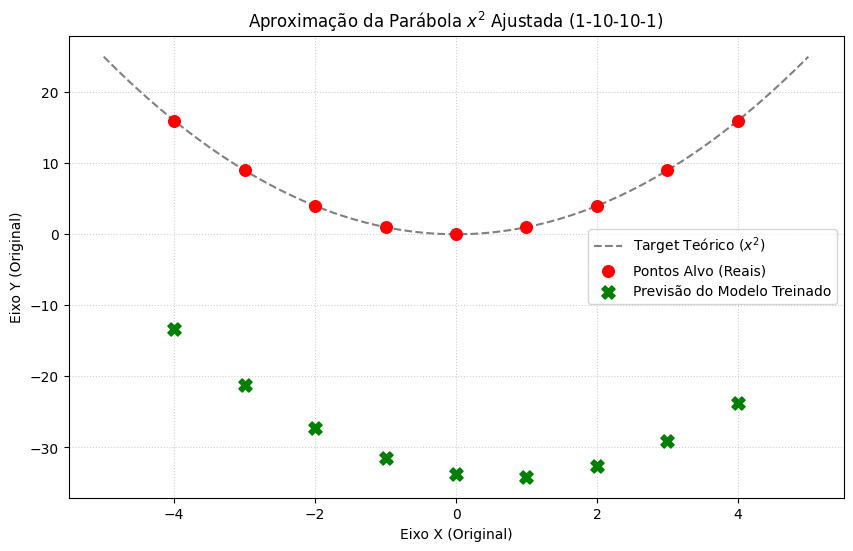

In [235]:
# ---- 1. Criação dos Dados de Treino Ampliados ----
dataX = np.linspace(-100, 100, 201)[:, np.newaxis]
# Força a inclusão dos pontos de teste dentro do treino para ancoragem
pontos_teste = np.array([[-4], [-3], [-2], [-1], [0], [1], [2], [3], [4]])
dataX = np.unique(np.vstack((dataX, pontos_teste)), axis=0)
dataY = dataX ** 2

# ---- 2. Normalização Segura ----
x_min, x_max = dataX.min(), dataX.max()
y_min, y_max = dataY.min(), dataY.max()

dataX_norm = (dataX - x_min) / (x_max - x_min)
dataY_norm = (dataY - y_min) / (y_max - y_min)
data_norm = np.hstack((dataX_norm, dataY_norm))

# ---- 3. Instanciação e Treino Otimizado ----
model = model2C(EPOCHS=30000, LR=0.1, TOL=1e-6, data=data_norm)
model.train()

# ---- 4. Preparação do Gráfico de Validação ----
import matplotlib.pyplot as plt

data1 = np.array([
    [-4, 16], [-3, 9], [-2, 4], [-1, 1], [0, 0], [1, 1], [2, 4], [3, 9], [4, 16]
])
x_val = data1[:, 0][:, np.newaxis]
y_val_real = data1[:, 1][:, np.newaxis]

# Normaliza usando os limites corretos do treino
x_val_norm = (x_val - x_min) / (x_max - x_min)
y_pred_norm = model.forward(x_val_norm)

# Desnormaliza a saída do modelo
y_val_predito = y_pred_norm * (y_max - y_min) + y_min

# ---- 5. Plotagem ----
plt.figure(figsize=(10, 6))
x_linha = np.linspace(-5, 5, 100)
plt.plot(x_linha, x_linha**2, color='gray', linestyle='--', label='Target Teórico ($x^2$)')
plt.scatter(x_val, y_val_real, color='red', s=70, zorder=3, label='Pontos Alvo (Reais)')
plt.scatter(x_val, y_val_predito, color='green', marker='X', s=90, zorder=4, label='Previsão do Modelo Treinado')

plt.xlabel('Eixo X (Original)')
plt.ylabel('Eixo Y (Original)')
plt.title('Aproximação da Parábola $x^2$ Ajustada (1-10-10-1)')
plt.legend()
plt.grid(True, linestyle=':', alpha=0.6)
plt.show()


In [293]:
import numpy as np

class model2C:
    def __init__(self, EPOCHS=10000, LR=0.05, delta=0.05, TOL=1e-5, data=None):
        np.random.seed(42)  # Semente estável para convergência com Tanh
        
        # Dimensões da Rede 1-10-10-1
        n_in, n_h1, n_h2, n_out = 1, 3, 3, 1
        
        # Inicialização de Xavier (Glorot) para Tanh
        self.W1 = np.random.randn(n_in, n_h1) * np.sqrt(2.0 / (n_in + n_h1))
        self.b1 = np.zeros((1, n_h1))
        
        self.W2 = np.random.randn(n_h1, n_h2) * np.sqrt(2.0 / (n_h1 + n_h2))
        self.b2 = np.zeros((1, n_h2))
        
        self.W3 = np.random.randn(n_h2, n_out) * np.sqrt(2.0 / (n_h2 + n_out))
        self.b3 = np.zeros((1, n_out))

        self.epochs = EPOCHS
        self.lr = LR
        self.tol = TOL
        self.data = data
        self.errors = []

    def tanh(self, x):
        return np.tanh(x)

    def d_tanh(self, x):
        return 1.0 - np.tanh(x) ** 2
    
    

    def error(self, yi, y):
        return np.mean((yi - y) ** 2)


    def forward(self, x):
        # Armazena h e a no self para reutilização no backprop
        self.h1 = x @ self.W1 + self.b1
        self.a1 = self.tanh(self.h1)
        
        self.h2 = self.a1 @ self.W2 + self.b2
        self.a2 = self.tanh(self.h2)
        
        self.h3 = self.a2 @ self.W3 + self.b3
        return self.h3

  
    def backprop_sobolev(self, x, y_true, dy_true, beta=0.001):
        m = x.shape[0]
        
        # 1. FORWARD DA INCLINAÇÃO
        # d_tanh de h1 e h2
        dt1 = self.d_tanh(self.h1) # shape: (m, 3)
        dt2 = self.d_tanh(self.h2) # shape: (m, 3)
        
        # dy_dx final da rede
        dy_dx = ((dt1 * self.W1) @ self.W2 * dt2) @ self.W3 # shape: (m, 1)
        
        # 2. CÁLCULO DOS COMPONENTES DE ERRO
        dL_val = 2 * (self.h3 - y_true)        # Erro de posição
        dL_grad = 2 * beta * (dy_dx - dy_true)  # Erro de Sobolev (inclinação)
        
        # ==========================================
        # PASSO A: Gradientes da perda de Posição (Idêntico ao seu)
        # ==========================================
        dw3_v = (self.a2.T @ dL_val) / m
        db3_v = np.sum(dL_val, axis=0, keepdims=True) / m
        
        dh2_v = (dL_val @ self.W3.T) * dt2
        dw2_v = (self.a1.T @ dh2_v) / m
        db2_v = np.sum(dh2_v, axis=0, keepdims=True) / m
        
        dh1_v = (dh2_v @ self.W2.T) * dt1
        dw1_v = (x.T @ dh1_v) / m
        db1_v = np.sum(dh1_v, axis=0, keepdims=True) / m

        # ==========================================
        # PASSO B: Gradientes aproximados da perda de Sobolev
        # ==========================================
        # Derivada segunda aproximada da Tanh: d2_tanh = -2 * tanh * d_tanh
        d2t1 = -2 * np.tanh(self.h1) * dt1
        d2t2 = -2 * np.tanh(self.h2) * dt2
        
        # Contribuição de Sobolev para W3
        out_grad_w3 = (dt1 * self.W1) @ self.W2 * dt2
        dw3_g = (out_grad_w3.T @ dL_grad) / m
        
        # Contribuição de Sobolev para W2 e b2
        dh2_g = (dL_grad @ self.W3.T) * d2t2 * ((dt1 * self.W1) @ self.W2) + (dL_grad @ self.W3.T) * dt2 * (dt1 * self.W1)
        dw2_g = (self.a1.T @ dh2_g) / m
        db2_g = np.sum(dh2_g, axis=0, keepdims=True) / m
        
        # Contribuição de Sobolev para W1 e b1
        dh1_g = (dL_grad @ self.W3.T) * dt2 @ self.W2.T * d2t1 * self.W1 + (dL_grad @ self.W3.T) * dt2 @ self.W2.T * dt1
        dw1_g = (x.T @ dh1_g) / m
        db1_g = np.sum(dh1_g, axis=0, keepdims=True) / m
        
        # ==========================================
        # PASSO C: ACUMULAÇÃO E ATUALIZAÇÃO DOS PESOS
        # ==========================================
        self.W3 -= self.lr * (dw3_v + dw3_g)
        self.b3 -= self.lr * db3_v # b3 não recebe erro de inclinação
        
        self.W2 -= self.lr * (dw2_v + dw2_g)
        self.b2 -= self.lr * (db2_v + db2_g)
        
        self.W1 -= self.lr * (dw1_v + dw1_g)
        self.b1 -= self.lr * (db1_v + db1_g)


    def train(self):
        print("Iniciando treinamento...")
        print(f"Pesos iniciais: W1={self.W1}, \nb1={self.b1}, \nW2={self.W2}, \nb2={self.b2}, \nW3={self.W3}, \nb3={self.b3}")
        x = self.data[:, 0][:, np.newaxis]
        y_true = self.data[:, 1][:, np.newaxis]
        
        for epoch in range(self.epochs):
            y_pred = self.forward(x)
            erro = self.error(y_pred, y_true)
            self.errors.append(erro)
            
            if erro < self.tol:
                print(f'💥 Convergiu na época {epoch}! Erro final: {erro:.6e}')
                break
                
            # Calcula a derivada da perda diretamente para passar ao backprop
            dL = 2 * (y_pred - y_true)
            self.backprop_sobolev(x, y_true, self.data[:, 2][:, np.newaxis])  # dy_true não é usado aqui
            
            if epoch % 100 == 0:
                print(f'Época: {epoch} | Erro: {erro:.4f}')



In [294]:
dataX = np.linspace(-4, 4, 20)[:, np.newaxis]
dataY = dataX ** 2
derivada_dataY = 2 * dataX  # Derivada de x^2 é 2x
datax_normalized = normalize_data(dataX, np.max(dataX), np.min(dataX))
datay_normalized = normalize_data(dataY, np.max(dataY), np.min(dataY))
data_derivada_normalized = normalize_data(derivada_dataY, np.max(derivada_dataY), np.min(derivada_dataY))
data = np.hstack((datax_normalized, datay_normalized, data_derivada_normalized))
# print(data)
# data = np.array([[2 , 4]]
                    
model = model2C(EPOCHS=100000, LR=0.05, TOL=1e-4, data=data)
model.train()

Iniciando treinamento...
Pesos iniciais: W1=[[ 0.35122995 -0.09776762  0.45798496]], 
b1=[[0. 0. 0.]], 
W2=[[ 0.8793217  -0.13518851 -0.13517904]
 [ 0.91175894  0.44307865 -0.27105116]
 [ 0.31324719 -0.26755433 -0.2688892 ]], 
b2=[[0. 0. 0.]], 
W3=[[ 0.17109316]
 [-1.35289344]
 [-1.2197011 ]], 
b3=[[0.]]
Época: 0 | Erro: 0.1464
Época: 100 | Erro: 0.1118
Época: 200 | Erro: 0.1095
Época: 300 | Erro: 0.1088
Época: 400 | Erro: 0.1085
Época: 500 | Erro: 0.1084
Época: 600 | Erro: 0.1084
Época: 700 | Erro: 0.1084
Época: 800 | Erro: 0.1083
Época: 900 | Erro: 0.1083
Época: 1000 | Erro: 0.1083
Época: 1100 | Erro: 0.1083
Época: 1200 | Erro: 0.1083
Época: 1300 | Erro: 0.1083
Época: 1400 | Erro: 0.1083
Época: 1500 | Erro: 0.1083
Época: 1600 | Erro: 0.1083
Época: 1700 | Erro: 0.1083
Época: 1800 | Erro: 0.1083
Época: 1900 | Erro: 0.1083
Época: 2000 | Erro: 0.1082
Época: 2100 | Erro: 0.1082
Época: 2200 | Erro: 0.1082
Época: 2300 | Erro: 0.1082
Época: 2400 | Erro: 0.1082
Época: 2500 | Erro: 0.1081
Époc

In [300]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np

# 1. Definição da Arquitetura (1-3-3-1 com Tanh)
class Model2CSobolev(nn.Module):
    def __init__(self):
        super(Model2CSobolev, self).__init__()
        self.net = nn.Sequential(
            nn.Linear(1, 3),
            nn.Tanh(),
            nn.Linear(3, 3),
            nn.Tanh(),
            nn.Linear(3, 1)
        )
        self._init_weights()

    def _init_weights(self):
        # Inicialização de Xavier/Glorot idêntica ao código manual
        for layer in self.net:
            if isinstance(layer, nn.Linear):
                nn.init.xavier_normal_(layer.weight)
                nn.init.zeros_(layer.bias)

    def forward(self, x):
        return self.net(x)

# 2. Preparação dos dados (Idêntico ao seu pipeline)
def normalize_data(data, d_max, d_min):
    return 2 * ((data - d_min) / (d_max - d_min)) - 1

dataX = np.linspace(-4, 4, 20)[:, np.newaxis]
dataY = dataX ** 2
derivada_dataY = 2 * dataX

x_norm = normalize_data(dataX, np.max(dataX), np.min(dataX))
y_norm = normalize_data(dataY, np.max(dataY), np.min(dataY))
dy_norm = 2*x_norm  # Derivada normalizada

# Conversão para tensores PyTorch (com gradiente habilitado no X para Sobolev)
X_tensor = torch.tensor(x_norm, dtype=torch.float32, requires_grad=True)
Y_tensor = torch.tensor(y_norm, dtype=torch.float32)
dY_tensor = torch.tensor(dy_norm, dtype=torch.float32)

# 3. Configuração do Treino
model_pt = Model2CSobolev()
optimizer = optim.SGD(model_pt.parameters(), lr=0.05)
epochs = 100000
beta = 0.05
tol = 1e-4

print("Iniciando treinamento com PyTorch...")
for epoch in range(epochs):
    optimizer.zero_grad()
    
    # Forward principal
    y_pred = model_pt(X_tensor)
    
    # Termo 1: Erro de Posição (MSE tradicional)
    loss_val = torch.mean((y_pred - Y_tensor) ** 2)
    
    # Termo 2: Erro de Sobolev (Gradiente)
    # torch.autograd.grad calcula a derivada da saída em relação à entrada X
    dy_dx_pred = torch.autograd.grad(
        outputs=y_pred,
        inputs=X_tensor,
        grad_outputs=torch.ones_like(y_pred),
        create_graph=True, # Mantém o grafo para derivar novamente no backprop global
        retain_graph=True
    )[0]
    
    loss_grad = torch.mean((dy_dx_pred - dY_tensor) ** 2)
    
    # Perda Total de Sobolev
    loss_total = loss_val + beta * loss_grad
    
    # Backpropagation automático (calcula todos os dW e db manuais para você)
    loss_total.backward()
    optimizer.step()
    
    if loss_val.item() < tol:
        print(f'💥 Convergiu na época {epoch}! Erro final: {loss_val.item():.6e}')
        break
        
    if epoch % 1000 == 0:
        print(f'Época: {epoch} | Perda Total: {loss_total.item():.4f} | MSE Valor: {loss_val.item():.4f}')


Iniciando treinamento com PyTorch...
Época: 0 | Perda Total: 0.5852 | MSE Valor: 0.5108
Época: 1000 | Perda Total: 0.0384 | MSE Valor: 0.0147
Época: 2000 | Perda Total: 0.0376 | MSE Valor: 0.0141
Época: 3000 | Perda Total: 0.0372 | MSE Valor: 0.0139
Época: 4000 | Perda Total: 0.0371 | MSE Valor: 0.0137
Época: 5000 | Perda Total: 0.0369 | MSE Valor: 0.0137
Época: 6000 | Perda Total: 0.0369 | MSE Valor: 0.0136
Época: 7000 | Perda Total: 0.0368 | MSE Valor: 0.0136
Época: 8000 | Perda Total: 0.0368 | MSE Valor: 0.0136
Época: 9000 | Perda Total: 0.0367 | MSE Valor: 0.0136
Época: 10000 | Perda Total: 0.0367 | MSE Valor: 0.0135
Época: 11000 | Perda Total: 0.0367 | MSE Valor: 0.0135
Época: 12000 | Perda Total: 0.0367 | MSE Valor: 0.0135
Época: 13000 | Perda Total: 0.0367 | MSE Valor: 0.0135
Época: 14000 | Perda Total: 0.0367 | MSE Valor: 0.0135
Época: 15000 | Perda Total: 0.0367 | MSE Valor: 0.0135
Época: 16000 | Perda Total: 0.0367 | MSE Valor: 0.0135
Época: 17000 | Perda Total: 0.0367 | MSE 

KeyboardInterrupt: 

In [309]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np

# 1. Gerando poucos dados de treino (onde a rede comum sofre)
np.random.seed(42)
x_raw = np.linspace(-3, 3, 12)[:, np.newaxis]  # Apenas 12 pontos de treino
y_raw = x_raw * np.sin(x_raw)
dy_raw = np.sin(x_raw) + x_raw * np.cos(x_raw)  # Derivada analítica

# 2. Normalização Correta com Fator de Escala para Sobolev
x_max, x_min = np.max(x_raw), np.min(x_raw)
y_max, y_min = np.max(y_raw), np.min(y_raw)

def normalize(data, d_max, d_min):
    return 2 * ((data - d_min) / (d_max - d_min)) - 1

x_norm = normalize(x_raw, x_max, x_min)
y_norm = normalize(y_raw, y_max, y_min)

# Fator de correção essencial para a derivada não quebrar a matemática
fator_escala = (x_max - x_min) / (y_max - y_min)
dy_norm = dy_raw * fator_escala

# Convertendo para Tensores do PyTorch
X = torch.tensor(x_norm, dtype=torch.float32, requires_grad=True)
Y = torch.tensor(y_norm, dtype=torch.float32)
dY = torch.tensor(dy_norm, dtype=torch.float32)

# 3. Arquitetura da Rede (Aumentamos um pouco para 1-10-10-1 para dar capacidade ao Seno)
class SobolevNet(nn.Module):
    def __init__(self):
        super(SobolevNet, self).__init__()
        self.net = nn.Sequential(
            nn.Linear(1, 10),
            nn.Tanh(),
            nn.Linear(10, 10),
            nn.Tanh(),
            nn.Linear(10, 1)
        )
    def forward(self, x):
        return self.net(x)

# 4. Loop de Treinamento com Perda Combinada
model = SobolevNet()
optimizer = optim.Adam(model.parameters(), lr=0.01) # Adam converge muito mais rápido aqui
beta = 0.1  # Peso do termo de Sobolev

for epoch in range(100000):
    optimizer.zero_grad()
    
    # Forward
    y_pred = model(X)
    
    # Termo 1: Erro de Posição
    loss_val = torch.mean((y_pred - Y) ** 2)
    
    # Termo 2: Erro de Inclinação (Sobolev)
    dy_dx_pred = torch.autograd.grad(
        outputs=y_pred,
        inputs=X,
        grad_outputs=torch.ones_like(y_pred),
        create_graph=True,
        retain_graph=True
    )[0]
    loss_grad = torch.mean((dy_dx_pred - dY) ** 2)
    
    # Perda Total
    loss_total = loss_val 
    if loss_total.item() < 1e-6:
        print(f'💥 Convergiu na época {epoch}! Perda final: {loss_total.item():.6e}')
        break
    loss_total.backward()
    optimizer.step()
    
    if epoch % 500 == 0:
        print(f"Época {epoch:4d} | MSE Valor: {loss_val.item():.4f} | MSE Gradiente: {loss_grad.item():.4f}")


Época    0 | MSE Valor: 0.5898 | MSE Gradiente: 26.4956
Época  500 | MSE Valor: 0.0001 | MSE Gradiente: 2.2766
Época 1000 | MSE Valor: 0.0000 | MSE Gradiente: 2.4749
Época 1500 | MSE Valor: 0.0000 | MSE Gradiente: 2.6676
Época 2000 | MSE Valor: 0.0000 | MSE Gradiente: 2.7983
Época 2500 | MSE Valor: 0.0012 | MSE Gradiente: 2.7370
Época 3000 | MSE Valor: 0.0000 | MSE Gradiente: 3.1053
💥 Convergiu na época 3052! Perda final: 9.979833e-07
